# 07 · XS-TS-target PCA — both targets, two-dimensional tuning

**Purpose.** Combine a cross-sectional loading target with a time-series target
(Bryzgalova et al., Proposition 3). It nests every other spectral model.

**Specification.** Top-$K$ eigenvectors $Q_K$ of
$\frac1{NT}C R'(I_T+\gamma_{TS}P_G)RC$, $C=I+\tilde\gamma P_\Lambda$;
$\hat\omega=\big(\tfrac{1}{\tilde\gamma+1}I+\tfrac{\tilde\gamma}{\tilde\gamma+1}P_\Lambda\big)Q_K$.
This solves $\min\frac1{NT}\mathrm{tr}(W_{TS}EW_{XS}E')$, $E=R-F\beta'$ (eq. 11).

| Parameter | Default |
|---|---|
| `n_factors`, `gamma_xs`, `gamma_ts` | 1, 1.0, 15.0 |
| `xs_target` | `"given"` / `"macro"` |
| `ts_target` | `"alpha"` / `"mean"` / `"comove"` / `"given"` |
| `publication_lag` | 0 |

### How to run this notebook

```bash
pip install -e ".[notebooks]"        # package + jupyter, matplotlib, pandas
jupyter lab examples/                 # or: jupyter notebook examples/
```

All data are **synthetic with known ground truth** (generated by
`lfm.simulate_factor_returns` / `lfm.simulate_ipca_panel`), so every cell runs
offline in seconds and estimates can be compared with the truth. To use your
own data, replace the simulation cell by a `pandas.DataFrame` of excess returns
(dates x assets); every estimator accepts DataFrames directly.

In [1]:
# Setup: imports, plotting defaults and reproducibility
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import latent_factor_models as lfm

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3})
print("latent-factor-models", lfm.__version__)

latent-factor-models 0.1.0


In [2]:
sim = lfm.simulate_factor_returns(T=600, N=100, seed=0)
data = sim.to_data("reference")
L, N = sim.xs_target.shape[1], 100

## 1. Two-dimensional cross-validation in parallel

Each (γ_XS, γ_TS, fold) triple is an independent task. With
`executor="process"` all cores are used; protect scripts with
`if __name__ == "__main__":` on Windows/macOS (not needed in notebooks with the
thread backend used here).

In [3]:
grid = {"gamma_xs": [0.0, L / N, 4 * L / N, 16 * L / N], "gamma_ts": [0.0, 5.0, 15.0, 50.0]}
gs = lfm.GridSearchCV(
    lfm.XSTSTargetPCA(3), grid, cv=5, scoring="sharpe", executor="thread", n_jobs=4
).fit(data)
heat = pd.DataFrame(gs.result_.to_records()).pivot(
    index="gamma_xs", columns="gamma_ts", values="mean_score"
)
print("best:", gs.best_params_)
heat

best: {'gamma_xs': 0.01, 'gamma_ts': 15.0}


gamma_ts,0.0,5.0,15.0,50.0
gamma_xs,,,,
0.00,0.2876,0.2895,0.2888,0.2870
0.01,0.2901,0.2910,0.2911,0.2909
0.04,0.2904,0.2906,0.2906,0.2905
0.16,0.2903,0.2901,0.2898,0.2896


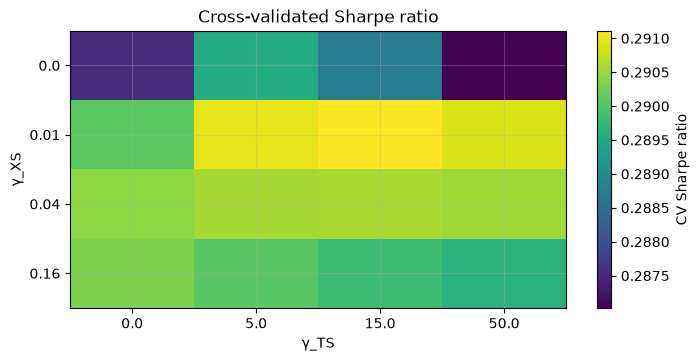

In [4]:
plt.imshow(heat.values, cmap="viridis", aspect="auto")
plt.xticks(range(heat.shape[1]), heat.columns)
plt.yticks(range(heat.shape[0]), np.round(heat.index, 3))
plt.xlabel("γ_TS")
plt.ylabel("γ_XS")
plt.colorbar(label="CV Sharpe ratio")
plt.title("Cross-validated Sharpe ratio");

## 2. The tuned model and its economic content

In [5]:
best = gs.best_model_
tm = best.target_metrics()
print(
    "XS-metric per factor:",
    np.round(tm["xs_metric"], 1),
    "| SDF:",
    round(tm["xs_metric_sdf"], 1),
    "| TS-metric:",
    round(tm["ts_metric"], 1),
)
pd.Series(best.evaluate(), name="tuned XS-TS-target PCA")

XS-metric per factor: [16.9 39.7 94.4] | SDF: 94.5 | TS-metric: 97.4


sharpe_ratio             0.3585
rms_alpha                0.1240
unexplained_variation    0.3374
total_r2                 0.7058
Name: tuned XS-TS-target PCA, dtype: float64

## 3. Comparison with the special cases

In [6]:
p = gs.best_params_
specs = {
    "PCA (second moment)": lfm.PCA(3, centered=False),
    "XS-target": lfm.XSTargetPCA(3, gamma_xs=p["gamma_xs"]),
    "TS-target": lfm.TSTargetPCA(3, gamma_ts=p["gamma_ts"]),
    "XS-TS-target": lfm.XSTSTargetPCA(3, **p),
}
pd.DataFrame({k: m.fit(data).evaluate() for k, m in specs.items()}).T

,sharpe_ratio,rms_alpha,unexplained_variation,total_r2
PCA (second moment),0.3311,0.1288,0.3371,0.7060
XS-target,0.3320,0.1284,0.3373,0.7059
TS-target,0.3814,0.1214,0.3374,0.7057
XS-TS-target,0.3585,0.1240,0.3374,0.7058


**Tips.** Use `TimeSeriesSplit` for strictly forward-looking validation
(`gap=` purges observations between train and test) and `scoring="neg_rms_alpha"`
if pricing errors matter more than the Sharpe ratio.

In [7]:
ts_cv = lfm.TimeSeriesSplit(n_splits=4, test_size=60, gap=1)
lfm.cross_validate(lfm.XSTSTargetPCA(3, **p), data, cv=ts_cv, scoring="neg_rms_alpha")

array([-0.4148, -0.3961, -0.3857, -0.371 ])